In [2]:
# Imports and environment first

import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from deepagents import create_deep_agent
from deepagents.backends import FilesystemBackend

load_dotenv(override=True)

True

In [3]:
search = GoogleSerperRun(api_wrapper=GoogleSerperAPIWrapper())

In [4]:
sandbox = os.path.abspath("sandbox")
os.makedirs(sandbox, exist_ok=True)

model = ChatOpenAI(model="gpt-5.4-mini")

researcher = create_deep_agent(
    model=model,
    tools=[search],
    system_prompt=(
        "You are a research analyst. Plan your work with your todo tool, "
        "research with the search tool, and write your findings as a tidy markdown briefing to a file."
    ),
    backend=FilesystemBackend(root_dir=sandbox, virtual_mode=True),
)

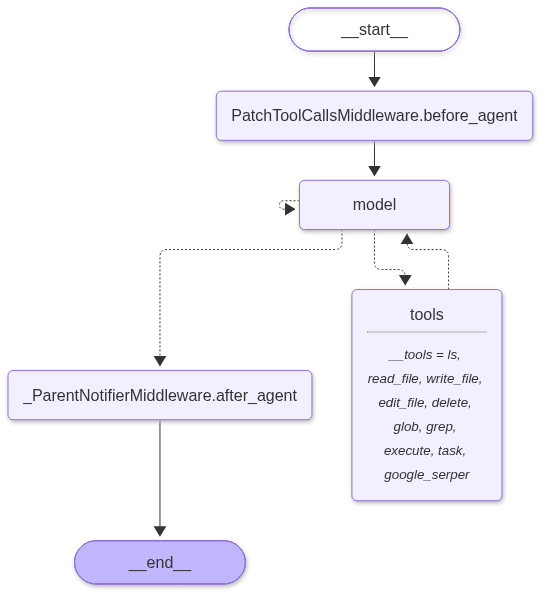

In [5]:
researcher

In [6]:
brief = """
Our company is planning to move its sales fleet to electric vehicles.
Research the public EV charging landscape in the Portugal: find out roughly how many public charging points there are,
and pick out two major charging networks a fleet could rely on.
Write a one page markdown briefing, with a heading and a short section for each, to the file charging.md.
"""

result = researcher.invoke({"messages": [{"role": "user", "content": brief}]})
print(result["messages"][-1].content)

Done — I wrote the one-page markdown briefing to `charging.md`.


In [7]:
tools_used = [tc["name"] for m in result["messages"] for tc in (getattr(m, "tool_calls", []) or [])]
print("Tools the agent called, in order:")
print(tools_used)

Tools the agent called, in order:
['ls', 'read_file', 'google_serper', 'google_serper', 'google_serper', 'write_file']


# Sub Agents

In [8]:
research_ev_instructions = """
You research one electric vehicle using the search tool and return three concise facts
that a fleet buyer would care about, such as price, range and charging.
"""

overall_instructions = """
You write comparison briefings for a company choosing electric vehicles for its sales fleet.
For each vehicle, delegate the research to your vehicle-researcher sub-agent,
then write a markdown comparison to a file, ending with a clear recommendation.
"""


research_subagent = {
    "name": "vehicle-researcher",
    "description": "Researches a single electric vehicle and returns a short list of facts about it.",
    "system_prompt": research_ev_instructions,
}

lead = create_deep_agent(
    model=model,
    tools=[search],
    system_prompt=overall_instructions,
    subagents=[research_subagent],
    backend=FilesystemBackend(root_dir=sandbox, virtual_mode=True),
)

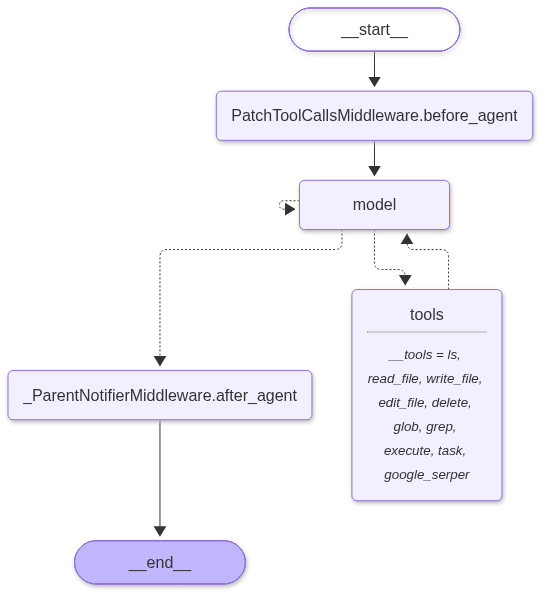

In [9]:
lead

In [10]:
mission = """
Compare the Tesla Model Y and the Ford Mustang Mach-E as candidates for our 100-car sales fleet.
Research each vehicle, then write a short markdown comparison with a recommendation to fleet.md.
"""

result = lead.invoke({"messages": [{"role": "user", "content": mission}]})

In [11]:
tools_used = [tc["name"] for m in result["messages"] for tc in (getattr(m, "tool_calls", []) or [])]
print("Tools the lead agent called:", tools_used)

Tools the lead agent called: ['task', 'task', 'write_file']


# Skills

In [12]:
from langchain_core.tools import tool
from slide_kit import build_slide

@tool
def create_slide(title: str, key_points: list[str], recommendation: str) -> str:
    """Create a one-slide PowerPoint in the Voltway Research house style, saved as fleet.pptx."""
    build_slide(title, key_points, recommendation, os.path.join(sandbox, "fleet.pptx"))
    return "Saved the slide to /fleet.pptx"

slide_maker = {
    "name": "slide-maker",
    "description": "Turns a finished recommendation into a one-slide PowerPoint deck.",
    "system_prompt": "You turn research recommendations into slides, following your fleet-slide skill.",
    "tools": [create_slide],
    "skills": ["/skills/"],
}

presenter = create_deep_agent(
    model=model,
    subagents=[slide_maker],
    system_prompt="You prepare research for presentation by delegating to your slide-maker sub-agent.",
    backend=FilesystemBackend(root_dir=sandbox, virtual_mode=True),
)

In [13]:
result = presenter.invoke({"messages": [{"role": "user", "content":
    "Read fleet.md and have a one-slide deck made of its recommendation."}]})
print(result["messages"][-1].content)

Here’s a one-slide deck draft based on `fleet.md`:

## Fleet pick: Tesla Model Y

- **Model Y range:** ~311–337 miles vs. Mach-E ~230–320; best for long sales routes
- **Charging simplicity:** Supercharger access and plug-and-charge reduce fleet friction
- **Cost tradeoff:** Mach-E is the cost-sensitive fallback  
  - Mach-E: ~$37,795–$57,335 MSRP  
  - Model Y: ~$44,990–$53,490 MSRP

**Recommendation:**  
Recommend **Tesla Model Y** as the default choice for a 100-car sales fleet; choose **Ford Mustang Mach-E** only if upfront cost is the main priority.

If you want, I can also turn this into a cleaner slide layout with a headline, two-column comparison, and a bold bottom-line callout.
